# Loss Functions Explained & Compared
### Classification · Segmentation · Detection: Every task asks the model a different question

The **loss** is the "question" we ask the model: *"How wrong were you?"*. The way the question is formulated determines what the model learns. This notebook explains the fundamental losses across 3 tasks and compares them practically with a fair methodology.

| Task | What We Compare | Core Concept |
|---|---|---|
| **A. Classification** (Imbalanced data + label noise) | CE · Weighted CE · Label Smoothing · Focal | Class probabilities: calibration and imbalance |
| **B. Segmentation** (Rare foreground) | BCE · Weighted BCE · Focal · Dice · BCE+Dice | Pixel-wise cross-entropy vs. direct overlap |
| **C. Detection** (Box regression) | L1 · Smooth-L1 · IoU · GIoU · GIoU+L1 | Coordinate matching vs. overlap metric itself |

**Comparison Methodology (in each part):**
1. **Each loss gets its best hyperparameters** on the validation set (not a single blanket setting for all).
2. **3 seeds for selection and 5 different seeds for final evaluation**, with results reported as mean $\pm$ std.
3. **The test set is evaluated only during the final runs.**
4. **Comparison is based on metrics, not loss values:** Loss values are not directly comparable across different losses.
5. **Implemented from scratch and verified** against PyTorch or manual calculations.
6. The optimizer is fixed (Adam, $\text{lr}=10^{-3}$), which is largely insensitive to loss scaling, making the comparison fairer.

> The data is intentionally synthetic: to control imbalance and size, and run in minutes. Results do **not** necessarily generalize to real-world data (see limitations at the end).

In [1]:
import os, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.ndimage import gaussian_filter
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE} | PyTorch {torch.__version__}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED_SWEEP, SEED_FINAL = [100, 101, 102], [0, 1, 2, 3, 4]
LR = 1e-3

def palette(names): return {n: f"C{i}" for i, n in enumerate(names)}
def ms(v): return f"{np.mean(v):.3f} ± {np.std(v):.3f}"
def hp_str(hp): return ", ".join(f"{k}={v}" for k, v in hp.items()) or "-"
def df_to_md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows(): lines.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lines)

def sweep_best(names, grids, train_fn, data, seeds=SEED_SWEEP, label=""):
    # hyperparameter selection on VALIDATION only (train_fn returns res['score'] = a validation metric)
    rows = []
    for name in names:
        for hp in grids[name]:
            for s in seeds:
                rows.append({"loss": name, "hp": hp_str(hp), "seed": s, "score": train_fn(name, hp, s, data)["score"]})
        print(f"[{label}] sweep done: {name}")
    sm = pd.DataFrame(rows).groupby(["loss", "hp"], sort=False)["score"].agg(["mean", "std"]).reset_index()
    best = {}
    for name in names:
        sub = sm[sm["loss"] == name]; key = sub.loc[sub["mean"].idxmax(), "hp"]
        best[name] = {hp_str(h): h for h in grids[name]}[key]
    return best, sm

def final_runs(names, best, train_fn, data, seeds=SEED_FINAL, label=""):
    final, models0 = {}, {}
    for name in names:
        runs = []
        for s in seeds:
            out = train_fn(name, best[name], s, data, final=True, keep_model=(s == seeds[0]))
            if s == seeds[0]: out, models0[name] = out
            runs.append(out)
        final[name] = runs
        print(f"[{label}] final runs done: {name} ({hp_str(best[name])})")
    return final, models0

Device: cuda | PyTorch 2.8.0+cu128


# Part A: Classification

## 1. The Losses
Let $z$ be the logits, $p = \text{softmax}(z)$, and $p_y$ be the probability of the correct class.

| Loss | Formula | Idea | Weakness |
|---|---|---|---|
| **Cross-Entropy (CE)** | $-\log p_y$ | The foundation of everything: maximizes the probability of the correct class (maximum likelihood) | Frequent classes dominate the gradient |
| **Weighted CE** | $w_y \cdot (-\log p_y)$ | Gives larger weights to rare classes | Can ruin calibration |
| **Label Smoothing** | $(1-\varepsilon)(-\log p_y) + \varepsilon \cdot \frac{1}{C}\sum_{c}(-\log p_c)$ | Prevents the model from becoming 100% confident (overconfidence) and helps with noisy labels | Reduces confidence even when it shouldn't |
| **Focal** | $-(1-p_y)^\gamma \log p_y$ | Down-weights easy examples ($p_y$ close to 1) to focus on hard ones | Requires tuning for $\gamma$ |

**Why does Focal loss work?** When $p_y = 0.95$, CE gives a small loss (though not zero), and when you have thousands of easy examples, they accumulate and drown out the hard ones. The term $(1-p_y)^\gamma$ scales down the easy examples close to zero.

In [2]:
def ce_loss(z, y, weight=None, label_smoothing=0.0):
    logp = F.log_softmax(z, 1)
    nll = -logp.gather(1, y[:, None])[:, 0]
    per = nll if label_smoothing == 0 else (1 - label_smoothing) * nll + label_smoothing * (-logp.mean(1))
    if weight is None: return per.mean()
    w = weight[y]; return (w * per).sum() / w.sum()

def focal_ce(z, y, gamma=2.0):
    lp = F.log_softmax(z, 1).gather(1, y[:, None])[:, 0]
    return (-(1 - lp.exp()) ** gamma * lp).mean()

CLS_LOSSES = {
    "CE":              lambda z, y: ce_loss(z, y),
    "Weighted CE":     lambda z, y, power: ce_loss(z, y, weight=(CLASS_COUNTS.sum() / (len(CLASS_COUNTS) * CLASS_COUNTS)) ** power),
    "Label smoothing": lambda z, y, eps: ce_loss(z, y, label_smoothing=eps),
    "Focal":           lambda z, y, gamma: focal_ce(z, y, gamma),
}
CLS_GRIDS = {"CE": [{}],
             "Weighted CE": [{"power": p} for p in (0.5, 1.0)],
             "Label smoothing": [{"eps": e} for e in (0.05, 0.1, 0.2)],
             "Focal": [{"gamma": g} for g in (1.0, 2.0, 3.0)]}
CLS_NAMES = list(CLS_GRIDS)

# ---- verification against PyTorch (float64) ----
torch.manual_seed(0)
zc = torch.randn(32, 3, dtype=torch.float64); yc = torch.randint(0, 3, (32,)); wc = torch.tensor([0.5, 1.0, 4.0], dtype=torch.float64)
checks = {
    "CE == F.cross_entropy":                       (ce_loss(zc, yc), F.cross_entropy(zc, yc)),
    "Weighted CE == F.cross_entropy(weight=...)":  (ce_loss(zc, yc, weight=wc), F.cross_entropy(zc, yc, weight=wc)),
    "Label smoothing == F.cross_entropy(label_smoothing=0.1)": (ce_loss(zc, yc, label_smoothing=0.1), F.cross_entropy(zc, yc, label_smoothing=0.1)),
    "Focal(gamma=0) == CE":                        (focal_ce(zc, yc, 0.0), ce_loss(zc, yc)),
}
verify_cls = pd.DataFrame([{"check": k, "max |diff|": f"{(a - b).abs().max().item():.2e}", "ok": (a - b).abs().max().item() < 1e-10} for k, (a, b) in checks.items()])
display(verify_cls); assert verify_cls["ok"].all()

,check,max |diff|,ok
0,CE == F.cross_entropy,0.00e+00,True
1,Weighted CE == F.cross_entropy(weight=...),2.22e-16,True
2,Label smoothing == F.cross_entropy(label_smoot...,0.00e+00,True
3,Focal(gamma=0) == CE,0.00e+00,True


## 2. Intuition: The gradient that makes a difference
Consider a positive example (`y = 1`) in the binary case, where $x$ is the logit: **negative** = the model is confidently wrong, **positive** = the model is confidently correct.
- **MSE on sigmoid** (for comparison purposes only): The gradient vanishes when the model is confidently wrong, meaning it stops learning from its worst mistakes. This is why we don't use it for classification.
- **BCE/CE:** The gradient remains continuous and active for large errors.
- **Focal:** Down-weights the gradient for easy examples ($z$ is positive) and shifts the focus toward hard ones. (Here, $\alpha = 1$ to isolate the effect of $(1-p)^\gamma$.)

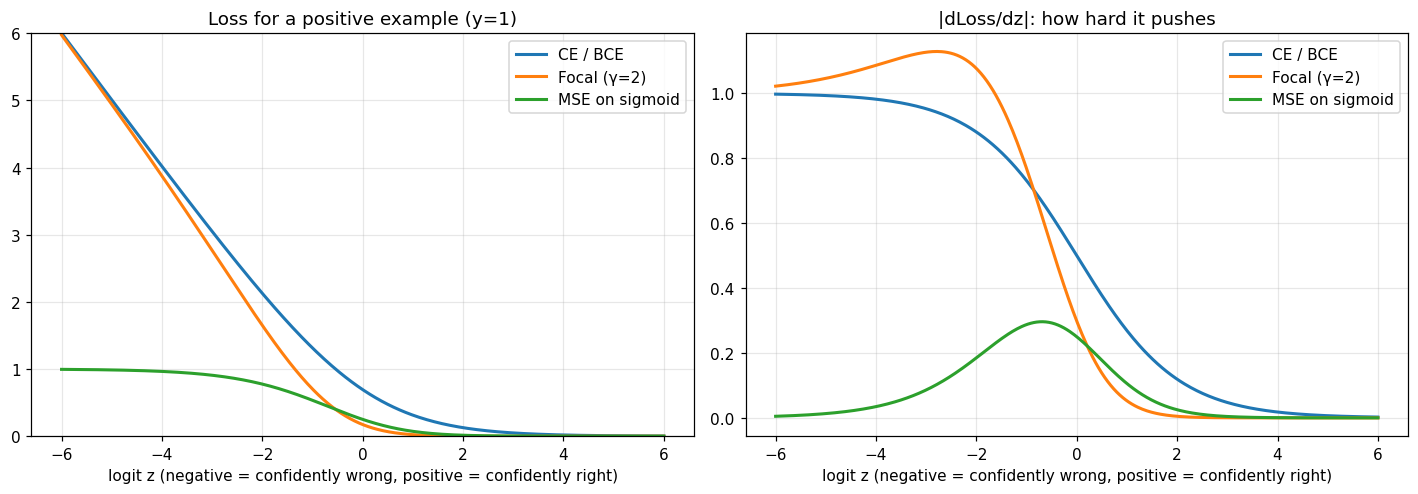

In [3]:
zz = torch.linspace(-6, 6, 400, requires_grad=True); p = torch.sigmoid(zz)
curves = {"CE / BCE": F.softplus(-zz), "Focal (γ=2)": (1 - p) ** 2 * F.softplus(-zz), "MSE on sigmoid": (p - 1) ** 2}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, l in curves.items():
    g, = torch.autograd.grad(l.sum(), zz, retain_graph=True)
    axes[0].plot(zz.detach(), l.detach(), lw=2, label=name); axes[1].plot(zz.detach(), g.abs().detach(), lw=2, label=name)
axes[0].set_title("Loss for a positive example (y=1)"); axes[1].set_title("|dLoss/dz|: how hard it pushes"); axes[0].set_ylim(0, 6)
for ax in axes: ax.set_xlabel("logit z (negative = confidently wrong, positive = confidently right)"); ax.legend()
plt.tight_layout(); fig.savefig("figures/01_loss_gradients.png", bbox_inches="tight"); plt.show()

## 3. Experiment
Synthetic tabular data: 3 classes with proportions of **80% / 15% / 5%** and 3% label noise. A small MLP model is used.

**Metrics:** Accuracy (misleading here) · **Macro-F1** · **Recall on the rare class** · NLL · **ECE** (Expected Calibration Error: measures how well the model's confidence matches its true accuracy; lower is better).
Model selection is based on **validation Macro-F1**. If your goal is calibration rather than F1, change the selection metric.

In [4]:
Xa, ya = make_classification(n_samples=8000, n_features=20, n_informative=8, n_redundant=4, n_classes=3,
                             n_clusters_per_class=2, weights=[0.80, 0.15, 0.05], flip_y=0.03, class_sep=1.0, random_state=42)
Xa_tr, Xa_tmp, ya_tr, ya_tmp = train_test_split(Xa, ya, test_size=0.4, random_state=42, stratify=ya)
Xa_va, Xa_te, ya_va, ya_te = train_test_split(Xa_tmp, ya_tmp, test_size=0.5, random_state=42, stratify=ya_tmp)
sc = StandardScaler().fit(Xa_tr)
tt = lambda X, dt: torch.tensor(sc.transform(X), dtype=dt, device=DEVICE)
cls_data = {"train": (tt(Xa_tr, torch.float32), torch.tensor(ya_tr, device=DEVICE)),
            "val":   (tt(Xa_va, torch.float32), torch.tensor(ya_va, device=DEVICE)),
            "test":  (tt(Xa_te, torch.float32), torch.tensor(ya_te, device=DEVICE))}
CLASS_COUNTS = torch.bincount(cls_data["train"][1], minlength=3).float()
print("train class counts:", CLASS_COUNTS.tolist(), "| majority-class baseline accuracy on test:", f"{(ya_te == 0).mean():.3f}")

def cls_metrics(logits, y, n_classes=3):
    p = F.softmax(logits, 1); pred = p.argmax(1); f1s, recs = [], []
    for c in range(n_classes):
        tp = ((pred == c) & (y == c)).sum().item(); fp = ((pred == c) & (y != c)).sum().item(); fn = ((pred != c) & (y == c)).sum().item()
        pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1); recs.append(rc); f1s.append(2 * pr * rc / max(pr + rc, 1e-12))
    conf, _ = p.max(1); correct = (pred == y).float(); ece = 0.0
    bins = torch.linspace(0, 1, 16, device=conf.device)
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.float().mean().item() * abs(correct[m].mean().item() - conf[m].mean().item())
    return {"acc": correct.mean().item(), "macro_f1": float(np.mean(f1s)), "minority_recall": recs[-1],
            "nll": F.nll_loss(torch.log(p.clamp_min(1e-12)), y).item(), "ece": ece}

def train_cls(name, hp, seed, data, final=False, keep_model=False, epochs=60, bs=128):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(20, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR); gen = torch.Generator().manual_seed(seed)
    Xtr, ytr = data["train"]; n = len(Xtr); fn = CLS_LOSSES[name]
    for _ in range(epochs):
        model.train(); perm = torch.randperm(n, generator=gen).to(DEVICE)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; opt.zero_grad(set_to_none=True); fn(model(Xtr[idx]), ytr[idx], **hp).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        res = {"score": cls_metrics(model(data["val"][0]), data["val"][1])["macro_f1"]}
        if final:
            zt = model(data["test"][0]); res["test"] = cls_metrics(zt, data["test"][1]); res["logits"] = zt.cpu()
    return (res, model) if keep_model else res

best_cls, sweep_cls = sweep_best(CLS_NAMES, CLS_GRIDS, train_cls, cls_data, label="cls")
print("Best:", {k: hp_str(v) for k, v in best_cls.items()}); display(sweep_cls)
final_cls, _ = final_runs(CLS_NAMES, best_cls, train_cls, cls_data, label="cls")

train class counts: [3773.0, 748.0, 279.0] | majority-class baseline accuracy on test: 0.786
[cls] sweep done: CE
[cls] sweep done: Weighted CE
[cls] sweep done: Label smoothing
[cls] sweep done: Focal
Best: {'CE': '-', 'Weighted CE': 'power=0.5', 'Label smoothing': 'eps=0.2', 'Focal': 'gamma=2.0'}


,loss,hp,mean,std
0,CE,-,0.795920,0.016341
1,Weighted CE,power=0.5,0.789357,0.015091
2,Weighted CE,power=1.0,0.759823,0.024636
3,Label smoothing,eps=0.05,0.816866,0.015436
4,Label smoothing,eps=0.1,0.815056,0.016427
5,Label smoothing,eps=0.2,0.819054,0.003481
6,Focal,gamma=1.0,0.784827,0.019599
7,Focal,gamma=2.0,0.792528,0.007620
8,Focal,gamma=3.0,0.787103,0.017230


[cls] final runs done: CE (-)
[cls] final runs done: Weighted CE (power=0.5)
[cls] final runs done: Label smoothing (eps=0.2)
[cls] final runs done: Focal (gamma=2.0)


,Best hyperparameters,Accuracy,Macro-F1,Minority recall,NLL,ECE
Loss,,,,,,
CE,-,0.925 ± 0.004,0.803 ± 0.012,0.513 ± 0.050,0.299 ± 0.012,0.028 ± 0.003
Weighted CE,power=0.5,0.917 ± 0.003,0.798 ± 0.006,0.567 ± 0.044,0.321 ± 0.010,0.025 ± 0.001
Label smoothing,eps=0.2,0.935 ± 0.002,0.822 ± 0.005,0.530 ± 0.022,0.312 ± 0.002,0.127 ± 0.003
Focal,gamma=2.0,0.921 ± 0.004,0.797 ± 0.009,0.533 ± 0.039,0.299 ± 0.012,0.064 ± 0.005


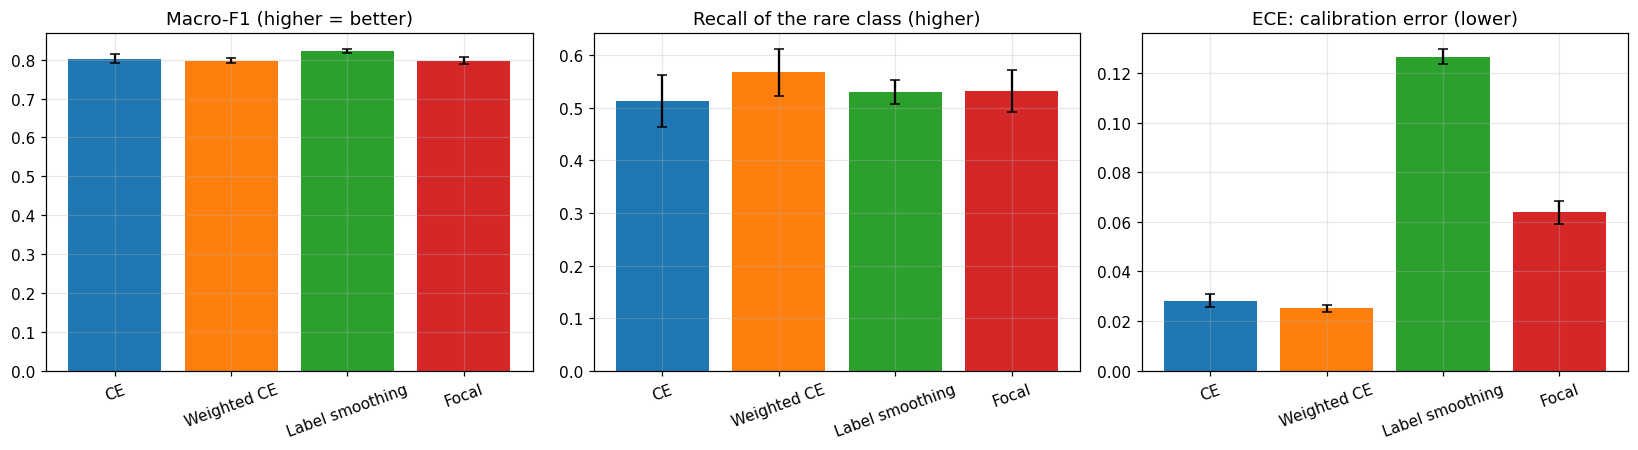

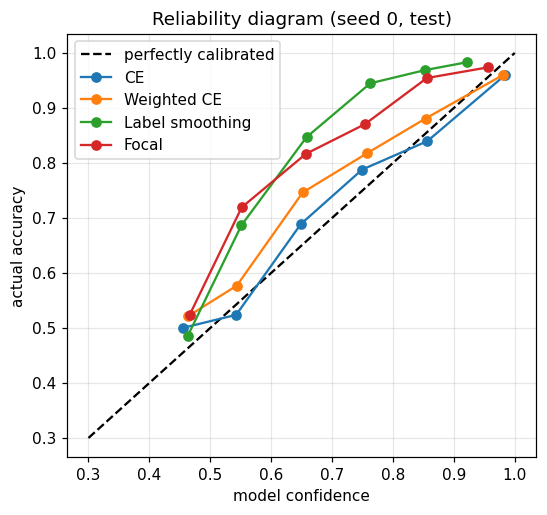

In [5]:
rows = []
for n in CLS_NAMES:
    r = [x["test"] for x in final_cls[n]]
    rows.append({"Loss": n, "Best hyperparameters": hp_str(best_cls[n]), "Accuracy": ms([x["acc"] for x in r]),
                 "Macro-F1": ms([x["macro_f1"] for x in r]), "Minority recall": ms([x["minority_recall"] for x in r]),
                 "NLL": ms([x["nll"] for x in r]), "ECE": ms([x["ece"] for x in r])})
cls_table = pd.DataFrame(rows); display(cls_table.set_index("Loss"))
open("results/classification.md", "w").write(df_to_md(cls_table))

pal = palette(CLS_NAMES); fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (key, title) in zip(axes, [("macro_f1", "Macro-F1 (higher = better)"), ("minority_recall", "Recall of the rare class (higher)"), ("ece", "ECE: calibration error (lower)")]):
    vals = [[x["test"][key] for x in final_cls[n]] for n in CLS_NAMES]
    ax.bar(range(len(CLS_NAMES)), [np.mean(v) for v in vals], yerr=[np.std(v) for v in vals], color=[pal[n] for n in CLS_NAMES], capsize=3)
    ax.set_xticks(range(len(CLS_NAMES))); ax.set_xticklabels(CLS_NAMES, rotation=20); ax.set_title(title)
plt.tight_layout(); fig.savefig("figures/02_classification_results.png", bbox_inches="tight"); plt.show()

def reliability_curve(logits, y, n_bins=10):
    p = F.softmax(logits, 1); conf, pred = p.max(1); correct = (pred == y).float(); xs, ys = [], []
    edges = torch.linspace(0, 1, n_bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 10: xs.append(conf[m].mean().item()); ys.append(correct[m].mean().item())
    return xs, ys
fig, ax = plt.subplots(figsize=(5.5, 5)); ax.plot([0.3, 1], [0.3, 1], "k--", label="perfectly calibrated")
yte_cpu = cls_data["test"][1].cpu()
for n in CLS_NAMES:
    xs, ys = reliability_curve(final_cls[n][0]["logits"], yte_cpu); ax.plot(xs, ys, "o-", color=pal[n], label=n)
ax.set_xlabel("model confidence"); ax.set_ylabel("actual accuracy"); ax.set_title("Reliability diagram (seed 0, test)"); ax.legend()
fig.savefig("figures/03_calibration.png", bbox_inches="tight"); plt.show()

# Part B: Segmentation

Segmentation is classification applied to **every pixel**, so the previously mentioned losses (BCE instead of CE for binary cases) still apply. However, a new problem arises: when the foreground is rare (like oil spills), the background pixels dominate the loss. To address this, overlap-based losses were introduced.

## 1. The Losses

Let $p = \sigma(z)$ for each pixel, and compute soft TP/FP/FN as: $\text{TP} = \sum p \cdot y$.

| Loss | Formula | Idea | Weakness |
|---|---|---|---|
| **BCE** | $-[y \log p + (1-y)\log(1-p)]$ | Pixel-wise cross-entropy: calibrated probabilities and stable gradients | Background overwhelms when the foreground is rare |
| **Weighted BCE** | Positive class $\times w$ | Compensates for class imbalance using a weight | Large $w$ leads to many false positives |
| **Focal** | $-\alpha_t (1-p_t)^\gamma \log p_t$ | Focuses on hard-to-classify pixels | Requires tuning for $\alpha$ and $\gamma$ |
| **Dice** | $1 - \frac{2\text{TP} + s}{2\text{TP} + \text{FP} + \text{FN} + s}$ | Directly optimizes overlap; insensitive to background size | Unstable gradients, uncalibrated probabilities |
| **BCE+Dice** | $\text{BCE} + \text{Dice}$ | Combines BCE stability with Dice overlap focus | — |

In [6]:
def bce_loss(z, y, pos_weight=1.0):
    return (pos_weight * y * F.softplus(-z) + (1 - y) * F.softplus(z)).mean()      # stable form
def focal_bin(z, y, alpha=0.75, gamma=2.0):
    p = torch.sigmoid(z); ce = y * F.softplus(-z) + (1 - y) * F.softplus(z)
    p_t = y * p + (1 - y) * (1 - p); a_t = y * alpha + (1 - y) * (1 - alpha)
    return (a_t * (1 - p_t) ** gamma * ce).mean()
def dice_loss(z, y, smooth=1.0):                  # over the whole batch, so empty masks do not give 0/0
    p = torch.sigmoid(z); return 1 - (2 * (p * y).sum() + smooth) / (p.sum() + y.sum() + smooth)

SEG_LOSSES = {
    "BCE":          lambda z, y: bce_loss(z, y),
    "Weighted BCE": lambda z, y, pos_weight: bce_loss(z, y, pos_weight),
    "Focal":        lambda z, y, alpha, gamma: focal_bin(z, y, alpha, gamma),
    "Dice":         lambda z, y: dice_loss(z, y),
    "BCE+Dice":     lambda z, y: bce_loss(z, y) + dice_loss(z, y),
}
SEG_GRIDS = {"BCE": [{}], "Weighted BCE": [{"pos_weight": w} for w in (10, 30, 100)],
             "Focal": [{"alpha": a, "gamma": g} for a in (0.5, 0.75) for g in (1.0, 2.0)], "Dice": [{}], "BCE+Dice": [{}]}
SEG_NAMES = list(SEG_GRIDS)

torch.manual_seed(0)
zs = torch.randn(4, 1, 16, 16, dtype=torch.float64); ys = (torch.rand(4, 1, 16, 16) > 0.9).double(); pw = torch.tensor(5.0, dtype=torch.float64)
zg = zs.clone().requires_grad_(True); bce_loss(zg, ys).backward(); zperfect = (2 * ys - 1) * 20
checks = {
    "BCE == F.binary_cross_entropy_with_logits":       (bce_loss(zs, ys), F.binary_cross_entropy_with_logits(zs, ys)),
    "Weighted BCE == F.bce_with_logits(pos_weight=5)": (bce_loss(zs, ys, 5.0), F.binary_cross_entropy_with_logits(zs, ys, pos_weight=pw)),
    "Focal(gamma=0, alpha=0.5) == 0.5 * BCE":          (focal_bin(zs, ys, 0.5, 0.0), 0.5 * bce_loss(zs, ys)),
    "dBCE/dz == (sigmoid(z) - y) / N":                 (zg.grad, (torch.sigmoid(zs) - ys) / zs.numel()),
    "Dice(perfect prediction) ~= 0":                   (dice_loss(zperfect, ys), torch.zeros((), dtype=torch.float64)),
}
verify_seg = pd.DataFrame([{"check": k, "max |diff|": f"{(a - b).abs().max().item():.2e}", "ok": (a - b).abs().max().item() < 1e-6} for k, (a, b) in checks.items()])
display(verify_seg); assert verify_seg["ok"].all()

,check,max |diff|,ok
0,BCE == F.binary_cross_entropy_with_logits,0.00e+00,True
1,Weighted BCE == F.bce_with_logits(pos_weight=5),0.00e+00,True
2,"Focal(gamma=0, alpha=0.5) == 0.5 * BCE",0.00e+00,True
3,dBCE/dz == (sigmoid(z) - y) / N,2.17e-19,True
4,Dice(perfect prediction) ~= 0,1.18e-08,True


## 2. The Experiment
Synthetic 64×64 images containing 1–3 blobs on a noisy background, with ~20% empty images, and the foreground accounting for about **2%** of the pixels. A small U-Net architecture is used.

- **Accuracy is misleading:** A model that predicts "all background" gets ~98% accuracy and a Dice score of 0. Therefore, the evaluation metrics used are Dice, IoU, Precision, and Recall (computed globally across all test pixels).
- **Thresholding:** For each model, the threshold is chosen on the validation set to maximize the Dice score, and the results at a 0.5 threshold are also reported.
- Model selection is based on **validation Dice**.

foreground = 1.98% of test pixels | 'all background' baseline: accuracy 98.02%, Dice 0.00


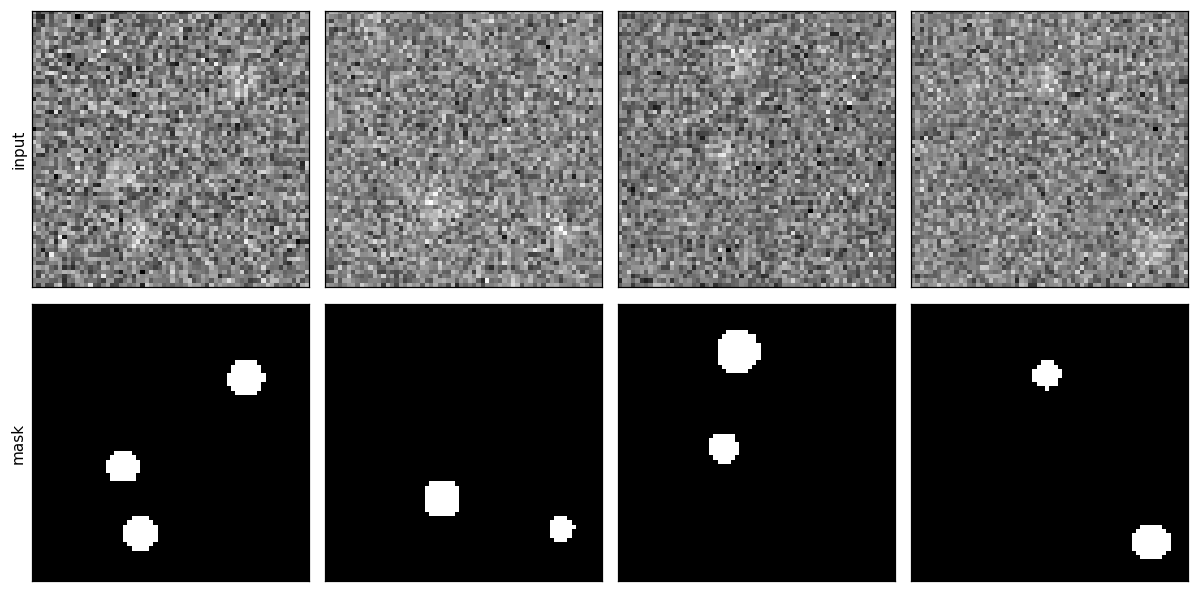

[seg] sweep done: BCE
[seg] sweep done: Weighted BCE
[seg] sweep done: Focal
[seg] sweep done: Dice
[seg] sweep done: BCE+Dice
Best: {'BCE': '-', 'Weighted BCE': 'pos_weight=100', 'Focal': 'alpha=0.5, gamma=1.0', 'Dice': '-', 'BCE+Dice': '-'}


,loss,hp,mean,std
0,BCE,-,0.860366,0.006853
1,Weighted BCE,pos_weight=10,0.855850,0.004867
2,Weighted BCE,pos_weight=30,0.857204,0.002593
3,Weighted BCE,pos_weight=100,0.859632,0.003020
4,Focal,"alpha=0.5, gamma=1.0",0.865510,0.004542
5,Focal,"alpha=0.5, gamma=2.0",0.861571,0.010449
6,Focal,"alpha=0.75, gamma=1.0",0.850781,0.008760
7,Focal,"alpha=0.75, gamma=2.0",0.862399,0.006787
8,Dice,-,0.862273,0.007191
9,BCE+Dice,-,0.853688,0.008877


[seg] final runs done: BCE (-)
[seg] final runs done: Weighted BCE (pos_weight=100)
[seg] final runs done: Focal (alpha=0.5, gamma=1.0)
[seg] final runs done: Dice (-)
[seg] final runs done: BCE+Dice (-)


In [7]:
SEG_FG, SEG_THRESHOLDS = 0.02, np.round(np.arange(0.05, 0.96, 0.05), 2)

def make_seg_dataset(n, fg, seed, size=64, p_empty=0.2, noise=0.8, contrast=1.0, sigma=1.0):
    rng = np.random.default_rng(seed); yy, xx = np.mgrid[:size, :size]
    X = np.zeros((n, 1, size, size), np.float32); Y = np.zeros_like(X)
    for i in range(n):
        mask = np.zeros((size, size), bool)
        if rng.random() > p_empty:
            k = int(rng.integers(1, 4)); area = fg * size * size / (1 - p_empty)
            for _ in range(k):
                r = np.sqrt(area / (k * np.pi)) * rng.uniform(0.7, 1.3)
                cy, cx = rng.uniform(r, size - r), rng.uniform(r, size - r)
                mask |= ((yy - cy) ** 2 + (xx - cx) ** 2) <= r * r
        X[i, 0] = contrast * gaussian_filter(mask.astype(np.float32), sigma=sigma) + rng.normal(0, noise, (size, size)).astype(np.float32)
        Y[i, 0] = mask
    return X, Y
seg_data = {}
for split, (n, seed) in {"train": (600, 101), "val": (200, 102), "test": (200, 103)}.items():
    X, Y = make_seg_dataset(n, SEG_FG, seed); seg_data[split] = (torch.tensor(X, device=DEVICE), torch.tensor(Y, device=DEVICE))
fg_test = seg_data["test"][1].mean().item()
print(f"foreground = {fg_test:.2%} of test pixels | 'all background' baseline: accuracy {1 - fg_test:.2%}, Dice 0.00")

fig, axes = plt.subplots(2, 4, figsize=(11, 5.6)); Xs_, Ys_ = seg_data["train"]
ids = [i for i in range(len(Ys_)) if Ys_[i].sum() > 0][:4]
for j, i in enumerate(ids):
    axes[0, j].imshow(Xs_[i, 0].cpu(), cmap="gray"); axes[1, j].imshow(Ys_[i, 0].cpu(), cmap="gray")
    for ax in axes[:, j]: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0, 0].set_ylabel("input"); axes[1, 0].set_ylabel("mask"); plt.tight_layout(); fig.savefig("figures/04_segmentation_data.png", bbox_inches="tight"); plt.show()

def conv_block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
class TinyUNet(nn.Module):
    def __init__(self, c=16):
        super().__init__()
        self.e1, self.e2, self.b = conv_block(1, c), conv_block(c, 2 * c), conv_block(2 * c, 4 * c); self.pool = nn.MaxPool2d(2)
        self.u2, self.d2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), conv_block(4 * c, 2 * c)
        self.u1, self.d1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), conv_block(2 * c, c); self.out = nn.Conv2d(c, 1, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1)); b = self.b(self.pool(e2))
        d2 = self.d2(torch.cat([self.u2(b), e2], 1)); d1 = self.d1(torch.cat([self.u1(d2), e1], 1)); return self.out(d1)

def predict_probs(model, X):
    model.eval()
    with torch.no_grad(): return torch.sigmoid(model(X))
def seg_metrics(probs, y, t):
    pred, yb = probs >= t, y > 0.5
    tp = (pred & yb).sum().item(); fp = (pred & ~yb).sum().item(); fn = (~pred & yb).sum().item(); tn = (~pred & ~yb).sum().item()
    return {"dice": 2 * tp / max(2 * tp + fp + fn, 1), "iou": tp / max(tp + fp + fn, 1), "precision": tp / max(tp + fp, 1),
            "recall": tp / max(tp + fn, 1), "accuracy": (tp + tn) / (tp + fp + fn + tn)}
def tune_threshold(pv, yv):
    sc_ = [seg_metrics(pv, yv, t)["dice"] for t in SEG_THRESHOLDS]; k = int(np.argmax(sc_)); return float(SEG_THRESHOLDS[k]), sc_[k]

def train_seg(name, hp, seed, data, final=False, keep_model=False, epochs=20, bs=32):
    torch.manual_seed(seed); model = TinyUNet().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed); Xtr, Ytr = data["train"]; n = len(Xtr); fn = SEG_LOSSES[name]
    for _ in range(epochs):
        model.train(); perm = torch.randperm(n, generator=gen).to(DEVICE)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; opt.zero_grad(set_to_none=True); fn(model(Xtr[idx]), Ytr[idx], **hp).backward(); opt.step()
    pv = predict_probs(model, data["val"][0]); thr, vd = tune_threshold(pv, data["val"][1])
    res = {"score": vd, "thr": thr}
    if final:
        pt = predict_probs(model, data["test"][0]); res["at_05"] = seg_metrics(pt, data["test"][1], 0.5); res["tuned"] = seg_metrics(pt, data["test"][1], thr)
    return (res, model) if keep_model else res

best_seg, sweep_seg = sweep_best(SEG_NAMES, SEG_GRIDS, train_seg, seg_data, label="seg")
print("Best:", {k: hp_str(v) for k, v in best_seg.items()}); display(sweep_seg)
final_seg, models_seg = final_runs(SEG_NAMES, best_seg, train_seg, seg_data, label="seg")

,Best hyperparameters,Dice @0.5,Dice @tuned thr,IoU,Precision,Recall,Pixel acc,Tuned thr (mean)
Loss,,,,,,,,
BCE,-,0.848 ± 0.011,0.859 ± 0.005,0.753 ± 0.008,0.864 ± 0.011,0.855 ± 0.008,0.9945,0.31
Weighted BCE,pos_weight=100,0.803 ± 0.016,0.852 ± 0.005,0.742 ± 0.007,0.844 ± 0.027,0.861 ± 0.028,0.9941,0.95
Focal,"alpha=0.5, gamma=1.0",0.846 ± 0.010,0.858 ± 0.006,0.752 ± 0.009,0.859 ± 0.004,0.858 ± 0.010,0.9944,0.35
Dice,-,0.848 ± 0.014,0.855 ± 0.008,0.747 ± 0.011,0.871 ± 0.015,0.841 ± 0.025,0.9944,0.14
BCE+Dice,-,0.839 ± 0.017,0.854 ± 0.008,0.745 ± 0.012,0.856 ± 0.010,0.851 ± 0.022,0.9942,0.40


Reference: 'all background' -> pixel accuracy 0.9802, Dice 0.000


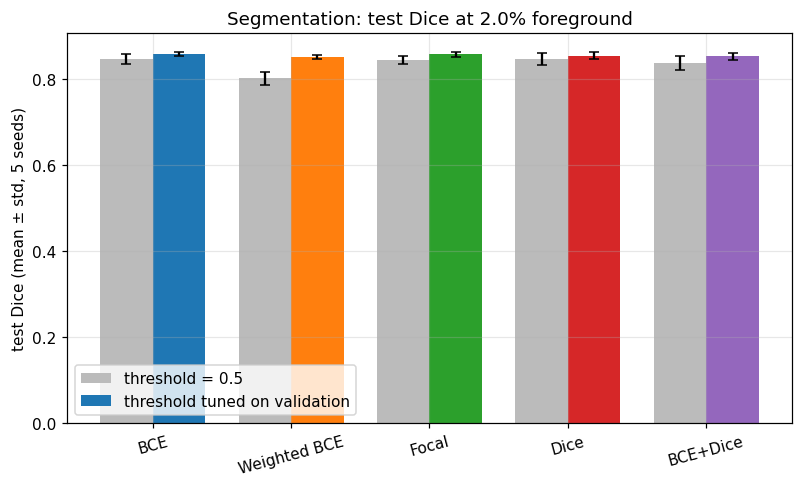

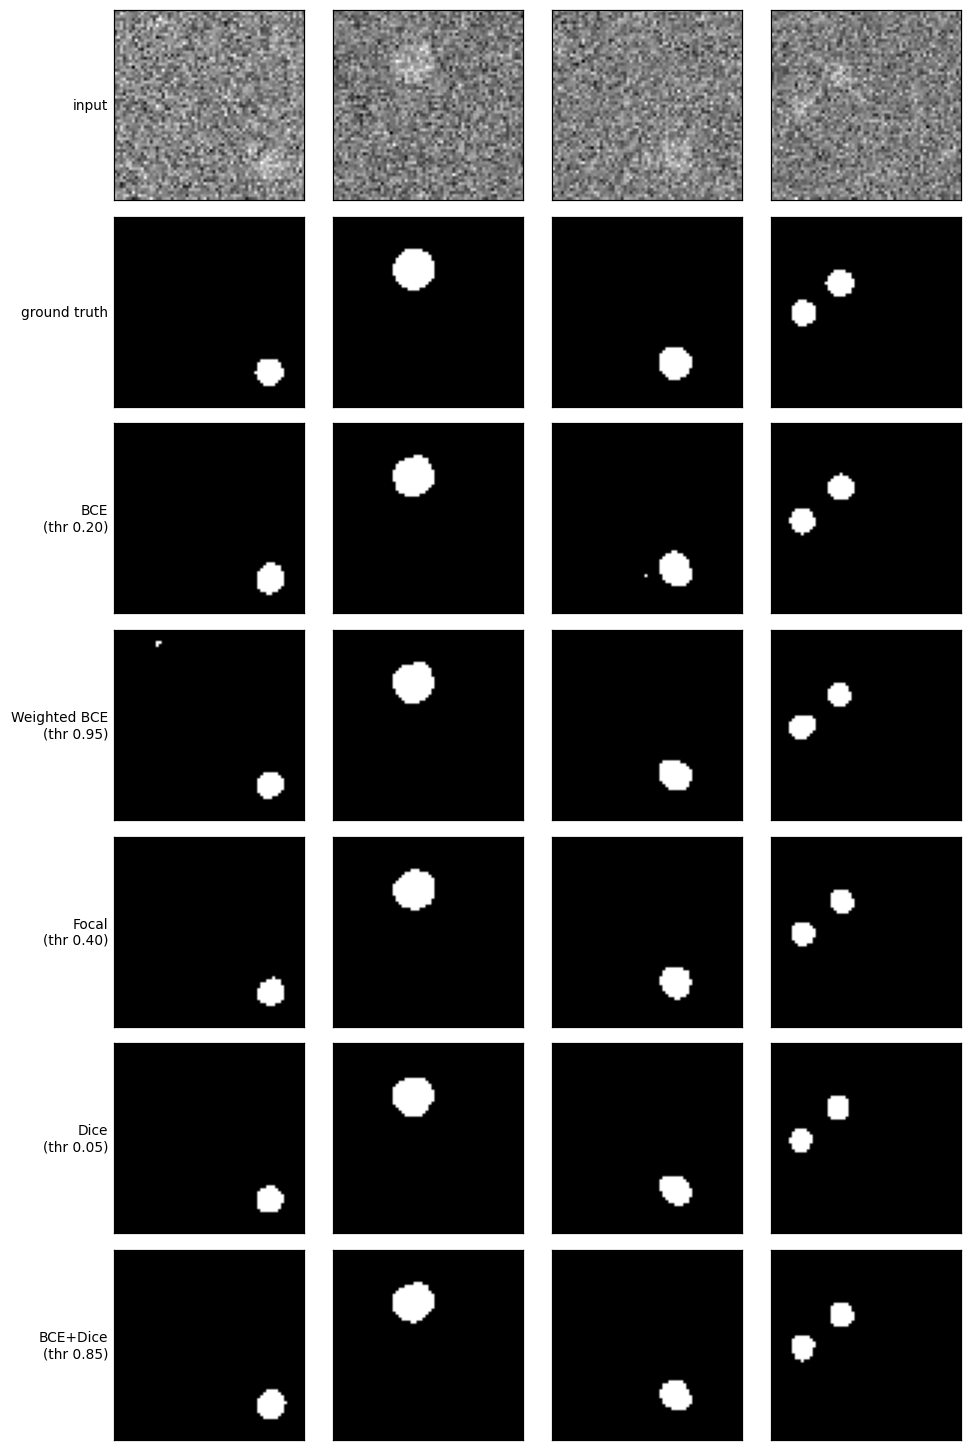

In [8]:
rows = []
for n in SEG_NAMES:
    r = final_seg[n]
    rows.append({"Loss": n, "Best hyperparameters": hp_str(best_seg[n]),
                 "Dice @0.5": ms([x["at_05"]["dice"] for x in r]), "Dice @tuned thr": ms([x["tuned"]["dice"] for x in r]),
                 "IoU": ms([x["tuned"]["iou"] for x in r]), "Precision": ms([x["tuned"]["precision"] for x in r]),
                 "Recall": ms([x["tuned"]["recall"] for x in r]), "Pixel acc": f"{np.mean([x['tuned']['accuracy'] for x in r]):.4f}",
                 "Tuned thr (mean)": f"{np.mean([x['thr'] for x in r]):.2f}"})
seg_table = pd.DataFrame(rows); display(seg_table.set_index("Loss"))
print(f"Reference: 'all background' -> pixel accuracy {1 - fg_test:.4f}, Dice 0.000")
open("results/segmentation.md", "w").write(df_to_md(seg_table))

pal = palette(SEG_NAMES); fig, ax = plt.subplots(figsize=(8.5, 4.6)); w = 0.38; xs = np.arange(len(SEG_NAMES))
d05 = [[x["at_05"]["dice"] for x in final_seg[n]] for n in SEG_NAMES]; dtu = [[x["tuned"]["dice"] for x in final_seg[n]] for n in SEG_NAMES]
ax.bar(xs - w / 2, [np.mean(v) for v in d05], w, yerr=[np.std(v) for v in d05], label="threshold = 0.5", color="#bbbbbb", capsize=3)
ax.bar(xs + w / 2, [np.mean(v) for v in dtu], w, yerr=[np.std(v) for v in dtu], label="threshold tuned on validation", color=[pal[n] for n in SEG_NAMES], capsize=3)
ax.set_xticks(xs); ax.set_xticklabels(SEG_NAMES, rotation=15); ax.set_ylabel("test Dice (mean ± std, 5 seeds)"); ax.set_title(f"Segmentation: test Dice at {fg_test:.1%} foreground"); ax.legend()
fig.savefig("figures/05_segmentation_results.png", bbox_inches="tight"); plt.show()

Xt, Yt = seg_data["test"]; idx = [i for i in range(len(Yt)) if Yt[i].sum() > 0][:4]; Xs, Ys = Xt[idx], Yt[idx]
fig, axes = plt.subplots(2 + len(SEG_NAMES), len(idx), figsize=(2.3 * len(idx), 1.9 * (2 + len(SEG_NAMES))))
rows_ = [("input", Xs.cpu()[:, 0]), ("ground truth", Ys.cpu()[:, 0])]
for n in SEG_NAMES:
    thr = final_seg[n][0]["thr"]; rows_.append((f"{n}\n(thr {thr:.2f})", (predict_probs(models_seg[n], Xs) >= thr).float().cpu()[:, 0]))
for r_, (lab, imgs) in enumerate(rows_):
    for c_ in range(len(idx)):
        axes[r_, c_].imshow(imgs[c_], cmap="gray"); axes[r_, c_].set_xticks([]); axes[r_, c_].set_yticks([]); axes[r_, c_].grid(False)
    axes[r_, 0].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout(); fig.savefig("figures/06_segmentation_predictions.png", bbox_inches="tight"); plt.show()

# Part C: Detection
The detector is trained on a **composite loss**: `total = classification loss + box-regression loss`.

1. **Classification** (Does this region contain an object or background? What is its class?): Uses the same CE/Focal losses mentioned previously. In detectors relying on thousands of anchors, the overwhelming majority are background, which is precisely why **Focal loss** (RetinaNet) was invented.
2. **Box Regression** (Where exactly is the box?): This is the new component, and we will compare the following:

| Loss | Idea | Weakness |
|---|---|---|
| **L1** | `|pred − target|` on box coordinates | The same pixel-level error is treated equally for small and large boxes, and it is not directly correlated with the actual metric (IoU) |
| **Smooth-L1** | Like L1, but quadratic near zero (`beta`) | Same problem, but with smoother gradients |
| **IoU loss** | `1 − IoU` | **Scale-invariant** and matches the evaluation metric. However, when boxes do not overlap, IoU = 0 and the **gradient = 0** |
| **GIoU loss** | `1 − GIoU`, where `GIoU = IoU − (area(C) − area(A∪B)) / area(C)` and C is the smallest enclosing box covering both | Provides gradients even when there is no overlap |
| **GIoU + L1** | `2·GIoU + w·L1` | A common combination (used in DETR) |

(Other variants like DIoU/CIoU incorporate center distance and aspect ratio, but they are not compared here.)

## 1. Implementation and Validation
The boxes are in `(x1, y1, x2, y2)` format.

In [9]:
def box_iou_giou(a, b, eps=1e-7):
    ix1 = torch.max(a[:, 0], b[:, 0]); iy1 = torch.max(a[:, 1], b[:, 1]); ix2 = torch.min(a[:, 2], b[:, 2]); iy2 = torch.min(a[:, 3], b[:, 3])
    inter = (ix2 - ix1).clamp(min=0) * (iy2 - iy1).clamp(min=0)
    area_a = (a[:, 2] - a[:, 0]).clamp(min=0) * (a[:, 3] - a[:, 1]).clamp(min=0)
    area_b = (b[:, 2] - b[:, 0]).clamp(min=0) * (b[:, 3] - b[:, 1]).clamp(min=0)
    union = area_a + area_b - inter; iou = inter / (union + eps)
    ex1 = torch.min(a[:, 0], b[:, 0]); ey1 = torch.min(a[:, 1], b[:, 1]); ex2 = torch.max(a[:, 2], b[:, 2]); ey2 = torch.max(a[:, 3], b[:, 3])
    enc = (ex2 - ex1) * (ey2 - ey1)
    return iou, iou - (enc - union) / (enc + eps)

def l1_box(p, t): return (p - t).abs().mean()
def smooth_l1_box(p, t, beta=0.1):
    d = (p - t).abs(); return torch.where(d < beta, 0.5 * d ** 2 / beta, d - 0.5 * beta).mean()
def iou_loss(p, t): return (1 - box_iou_giou(p, t)[0]).mean()
def giou_loss(p, t): return (1 - box_iou_giou(p, t)[1]).mean()

DET_LOSSES = {
    "L1":        lambda p, t: l1_box(p, t),
    "Smooth-L1": lambda p, t, beta: smooth_l1_box(p, t, beta),
    "IoU":       lambda p, t: iou_loss(p, t),
    "GIoU":      lambda p, t: giou_loss(p, t),
    "GIoU+L1":   lambda p, t, w: 2 * giou_loss(p, t) + w * l1_box(p, t),
}
DET_GRIDS = {"L1": [{}], "Smooth-L1": [{"beta": b} for b in (0.02, 0.1)], "IoU": [{}], "GIoU": [{}], "GIoU+L1": [{"w": w} for w in (1.0, 5.0)]}
DET_NAMES = list(DET_GRIDS)

# ---- verification: hand-computed cases + PyTorch ----
A = torch.tensor([[0, 0, 2, 2.], [0, 0, 1, 1.], [0, 0, 1, 1.]]); B = torch.tensor([[1, 1, 3, 3.], [2, 0, 3, 1.], [0, 0, 1, 1.]])
iou_v, giou_v = [t.tolist() for t in box_iou_giou(A, B)]
rows = [
    {"check": "IoU  of overlapping boxes = 1/7",   "got": f"{iou_v[0]:.5f}",  "expected": f"{1/7:.5f}",   "ok": bool(abs(iou_v[0] - 1/7) < 1e-5)},
    {"check": "GIoU of overlapping boxes = -5/63", "got": f"{giou_v[0]:.5f}", "expected": f"{-5/63:.5f}", "ok": bool(abs(giou_v[0] + 5/63) < 1e-5)},
    {"check": "IoU  of disjoint boxes = 0",        "got": f"{iou_v[1]:.5f}",  "expected": "0.00000",      "ok": bool(abs(iou_v[1]) < 1e-5)},
    {"check": "GIoU of disjoint boxes = -1/3",     "got": f"{giou_v[1]:.5f}", "expected": f"{-1/3:.5f}",  "ok": bool(abs(giou_v[1] + 1/3) < 1e-5)},
    {"check": "IoU and GIoU of identical boxes = 1", "got": f"{iou_v[2]:.5f} / {giou_v[2]:.5f}", "expected": "1 / 1", "ok": bool(abs(iou_v[2] - 1) < 1e-5 and abs(giou_v[2] - 1) < 1e-5)},
]
rnd_p, rnd_t = torch.rand(6, 2) * 0.4, torch.rand(6, 2) * 0.4
P = torch.cat([rnd_p, rnd_p + 0.1 + torch.rand(6, 2) * 0.4], 1); T = torch.cat([rnd_t, rnd_t + 0.1 + torch.rand(6, 2) * 0.4], 1)
dsl = (smooth_l1_box(P.double(), T.double(), 0.1) - F.smooth_l1_loss(P.double(), T.double(), beta=0.1)).abs().item()
rows.append({"check": "Smooth-L1 == F.smooth_l1_loss(beta=0.1)", "got": f"{dsl:.1e}", "expected": "0", "ok": bool(dsl < 1e-10)})
try:
    from torchvision.ops import box_iou, generalized_box_iou
    dd = max((torch.diag(box_iou(P, T)) - box_iou_giou(P, T)[0]).abs().max().item(), (torch.diag(generalized_box_iou(P, T)) - box_iou_giou(P, T)[1]).abs().max().item())
    rows.append({"check": "IoU/GIoU == torchvision.ops", "got": f"{dd:.1e}", "expected": "0", "ok": bool(dd < 1e-5)})
except ImportError:
    print("torchvision not installed: skipping the torchvision cross-check")
verify_det = pd.DataFrame(rows); display(verify_det); assert verify_det["ok"].all()

,check,got,expected,ok
0,IoU of overlapping boxes = 1/7,0.14286,0.14286,True
1,GIoU of overlapping boxes = -5/63,-0.07937,-0.07937,True
2,IoU of disjoint boxes = 0,0.00000,0.00000,True
3,GIoU of disjoint boxes = -1/3,-0.33333,-0.33333,True
4,IoU and GIoU of identical boxes = 1,1.00000 / 1.00000,1 / 1,True
5,Smooth-L1 == F.smooth_l1_loss(beta=0.1),0.0e+00,0,True
6,IoU/GIoU == torchvision.ops,4.2e-07,0,True


## 2. Intuition: The gradient when boxes are far apart
We fix the target box at `(0,0,1,1)` and move the prediction (of the same size) horizontally by a distance `d`. When `|d| > 1`, there is no intersection.
- **IoU loss** stays constant at 1 and the **gradient is zero**: the model doesn't know which direction to move.
- **GIoU** still provides a gradient because it accounts for the enclosing box area.

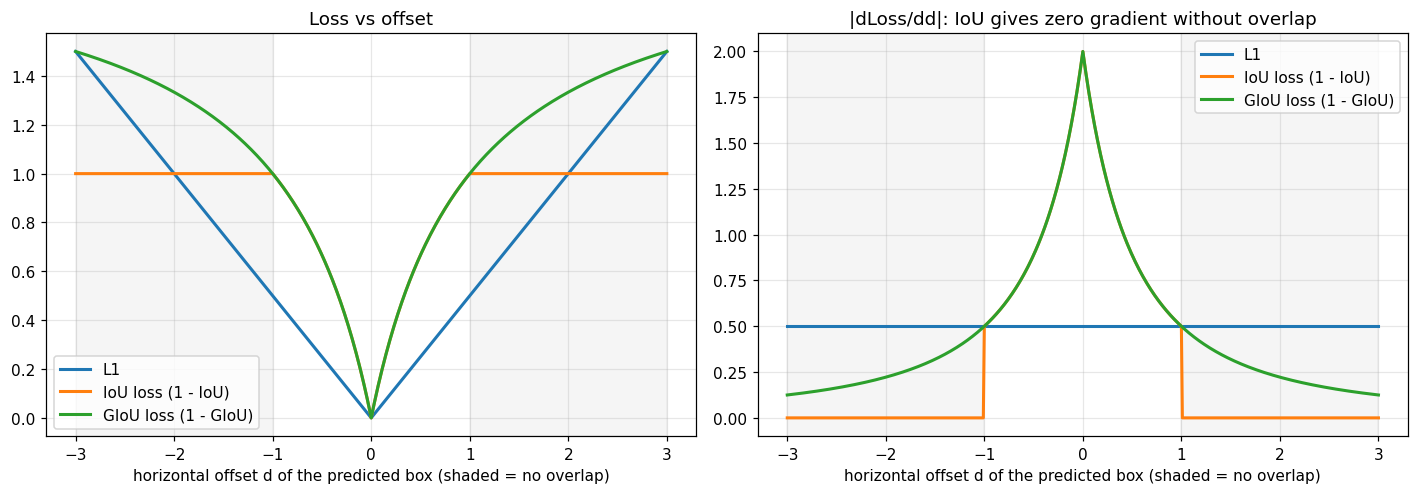

In [10]:
d = torch.linspace(-3, 3, 601, requires_grad=True)
pred = torch.stack([d, torch.zeros_like(d), d + 1, torch.ones_like(d)], 1)
tgt = torch.tensor([[0., 0., 1., 1.]]).expand(len(d), 4)
iou_, giou_ = box_iou_giou(pred, tgt)
curves = {"L1": (pred - tgt).abs().mean(1), "IoU loss (1 - IoU)": 1 - iou_, "GIoU loss (1 - GIoU)": 1 - giou_}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, l in curves.items():
    g, = torch.autograd.grad(l.sum(), d, retain_graph=True)
    axes[0].plot(d.detach(), l.detach(), lw=2, label=name); axes[1].plot(d.detach(), g.abs().detach(), lw=2, label=name)
for ax in axes:
    ax.axvspan(-3, -1, alpha=0.08, color="gray"); ax.axvspan(1, 3, alpha=0.08, color="gray")
    ax.set_xlabel("horizontal offset d of the predicted box (shaded = no overlap)"); ax.legend()
axes[0].set_title("Loss vs offset"); axes[1].set_title("|dLoss/dd|: IoU gives zero gradient without overlap")
plt.tight_layout(); fig.savefig("figures/07_box_loss_intuition.png", bbox_inches="tight"); plt.show()

## 3. Experiment: Object localization
A 64×64 image containing **a single rectangle** of random size (from 4 to 40 pixels) on a noisy background, and the CNN predicts the box. Sizes are intentionally varied to see if the loss behaves differently for **small** boxes (area < 150 px²) versus **large** boxes (> 800 px²).

**Metrics:** Mean IoU · Percentage of boxes with IoU > 0.5 and > 0.75 (standard detection metrics) · Mean IoU for small and large boxes. Model selection is based on **validation mean IoU**.

In [11]:
def make_box_dataset(n, seed, size=64, noise=0.5):
    rng = np.random.default_rng(seed); X = np.zeros((n, 1, size, size), np.float32); Bx = np.zeros((n, 4), np.float32)
    for i in range(n):
        w, h = rng.uniform(4, 40), rng.uniform(4, 40); x1, y1 = rng.uniform(0, size - w), rng.uniform(0, size - h)
        img = rng.normal(0, noise, (size, size)).astype(np.float32)
        img[int(round(y1)):int(round(y1 + h)), int(round(x1)):int(round(x1 + w))] += 1.0
        X[i, 0] = img; Bx[i] = [x1, y1, x1 + w, y1 + h]
    return X, Bx / size
det_data = {}
for split, (n, seed) in {"train": (2000, 201), "val": (400, 202), "test": (400, 203)}.items():
    X, Bx = make_box_dataset(n, seed); det_data[split] = (torch.tensor(X, device=DEVICE), torch.tensor(Bx, device=DEVICE))

class BoxNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 4))
    def forward(self, x):
        cx, cy, w, h = torch.sigmoid(self.f(x)).unbind(1)       # centre/size in [0, 1]
        return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)

def det_metrics(pred, tgt, size=64):
    iou, _ = box_iou_giou(pred, tgt); area = (tgt[:, 2] - tgt[:, 0]) * (tgt[:, 3] - tgt[:, 1]) * size * size
    small, large = area < 150, area > 800
    return {"miou": iou.mean().item(), "iou50": (iou > 0.5).float().mean().item(), "iou75": (iou > 0.75).float().mean().item(),
            "miou_small": iou[small].mean().item() if small.any() else float("nan"), "miou_large": iou[large].mean().item() if large.any() else float("nan")}

def train_det(name, hp, seed, data, final=False, keep_model=False, epochs=30, bs=64):
    torch.manual_seed(seed); model = BoxNet().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed); Xtr, Btr = data["train"]; n = len(Xtr); fn = DET_LOSSES[name]
    for _ in range(epochs):
        model.train(); perm = torch.randperm(n, generator=gen).to(DEVICE)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; opt.zero_grad(set_to_none=True); fn(model(Xtr[idx]), Btr[idx], **hp).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        res = {"score": det_metrics(model(data["val"][0]), data["val"][1])["miou"]}
        if final: res["test"] = det_metrics(model(data["test"][0]), data["test"][1])
    return (res, model) if keep_model else res

best_det, sweep_det = sweep_best(DET_NAMES, DET_GRIDS, train_det, det_data, label="det")
print("Best:", {k: hp_str(v) for k, v in best_det.items()}); display(sweep_det)
final_det, models_det = final_runs(DET_NAMES, best_det, train_det, det_data, label="det")

[det] sweep done: L1
[det] sweep done: Smooth-L1
[det] sweep done: IoU
[det] sweep done: GIoU
[det] sweep done: GIoU+L1
Best: {'L1': '-', 'Smooth-L1': 'beta=0.02', 'IoU': '-', 'GIoU': '-', 'GIoU+L1': 'w=1.0'}


,loss,hp,mean,std
0,L1,-,0.826406,0.018682
1,Smooth-L1,beta=0.02,0.837470,0.010217
2,Smooth-L1,beta=0.1,0.833751,0.006925
3,IoU,-,0.827883,0.018817
4,GIoU,-,0.845730,0.002792
5,GIoU+L1,w=1.0,0.844435,0.000992
6,GIoU+L1,w=5.0,0.838817,0.007098


[det] final runs done: L1 (-)
[det] final runs done: Smooth-L1 (beta=0.02)
[det] final runs done: IoU (-)
[det] final runs done: GIoU (-)
[det] final runs done: GIoU+L1 (w=1.0)


,Best hyperparameters,Mean IoU,IoU>0.5,IoU>0.75,Mean IoU (small boxes),Mean IoU (large boxes)
Loss,,,,,,
L1,-,0.850 ± 0.006,0.982 ± 0.004,0.854 ± 0.017,0.676 ± 0.014,0.931 ± 0.004
Smooth-L1,beta=0.02,0.858 ± 0.011,0.983 ± 0.007,0.878 ± 0.018,0.700 ± 0.023,0.935 ± 0.004
IoU,-,0.850 ± 0.009,0.983 ± 0.005,0.860 ± 0.030,0.685 ± 0.022,0.925 ± 0.006
GIoU,-,0.856 ± 0.006,0.985 ± 0.003,0.876 ± 0.014,0.705 ± 0.021,0.925 ± 0.006
GIoU+L1,w=1.0,0.855 ± 0.004,0.987 ± 0.002,0.871 ± 0.022,0.699 ± 0.009,0.929 ± 0.002


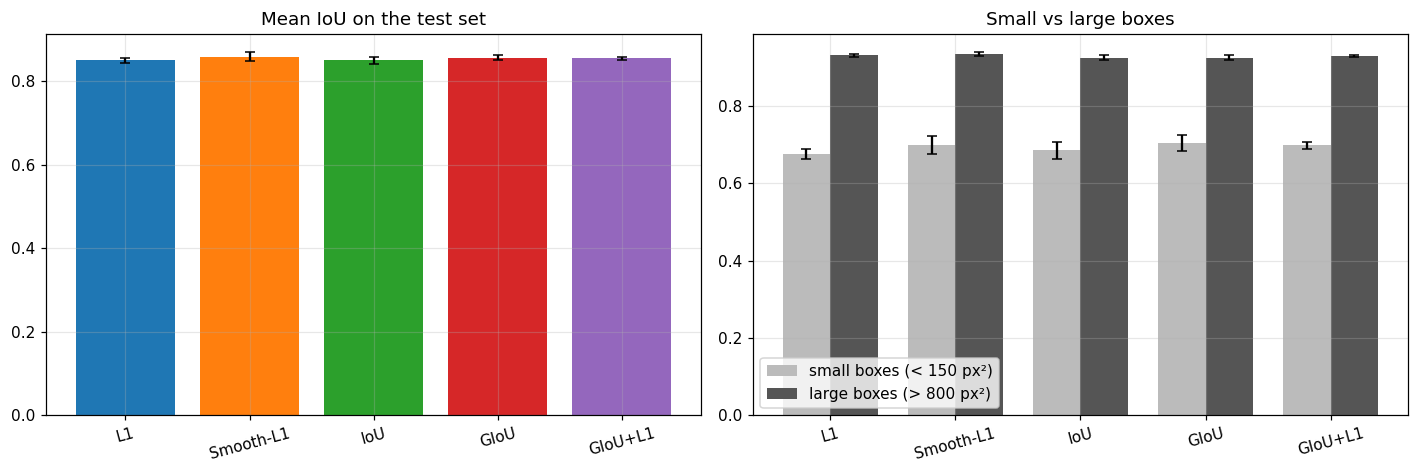

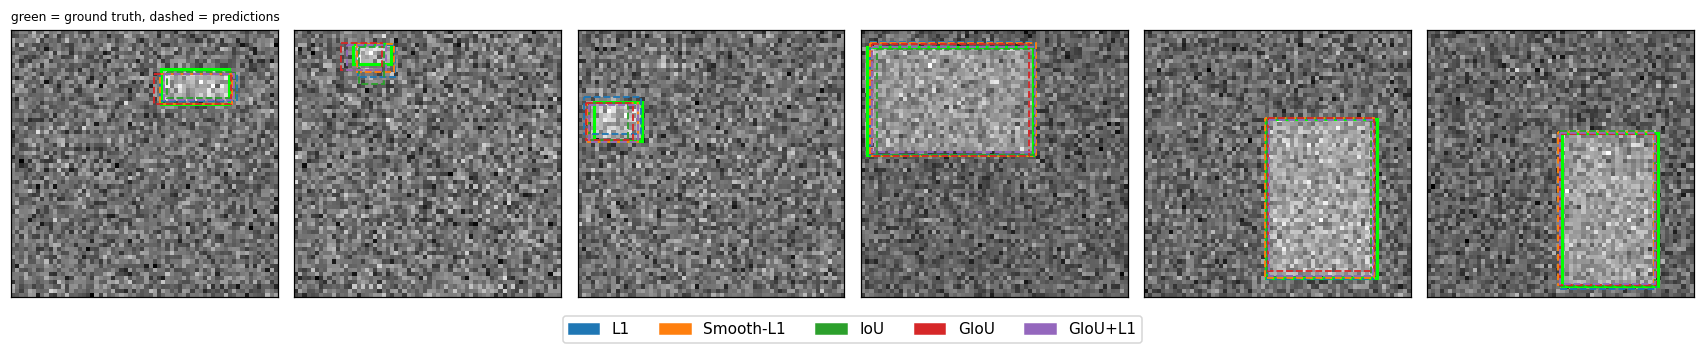

In [12]:
rows = []
for n in DET_NAMES:
    r = [x["test"] for x in final_det[n]]
    rows.append({"Loss": n, "Best hyperparameters": hp_str(best_det[n]), "Mean IoU": ms([x["miou"] for x in r]),
                 "IoU>0.5": ms([x["iou50"] for x in r]), "IoU>0.75": ms([x["iou75"] for x in r]),
                 "Mean IoU (small boxes)": ms([x["miou_small"] for x in r]), "Mean IoU (large boxes)": ms([x["miou_large"] for x in r])})
det_table = pd.DataFrame(rows); display(det_table.set_index("Loss"))
open("results/detection.md", "w").write(df_to_md(det_table))

pal = palette(DET_NAMES); fig, axes = plt.subplots(1, 2, figsize=(13, 4.4)); xs = np.arange(len(DET_NAMES)); w = 0.38
for ax, key, title in [(axes[0], "miou", "Mean IoU on the test set"), (axes[1], None, "Small vs large boxes")]:
    if key:
        v = [[x["test"][key] for x in final_det[n]] for n in DET_NAMES]
        ax.bar(xs, [np.mean(a) for a in v], yerr=[np.std(a) for a in v], color=[pal[n] for n in DET_NAMES], capsize=3)
    else:
        vs = [[x["test"]["miou_small"] for x in final_det[n]] for n in DET_NAMES]; vl = [[x["test"]["miou_large"] for x in final_det[n]] for n in DET_NAMES]
        ax.bar(xs - w / 2, [np.mean(a) for a in vs], w, yerr=[np.std(a) for a in vs], label="small boxes (< 150 px²)", color="#bbbbbb", capsize=3)
        ax.bar(xs + w / 2, [np.mean(a) for a in vl], w, yerr=[np.std(a) for a in vl], label="large boxes (> 800 px²)", color="#555555", capsize=3); ax.legend()
    ax.set_xticks(xs); ax.set_xticklabels(DET_NAMES, rotation=15); ax.set_title(title)
plt.tight_layout(); fig.savefig("figures/08_detection_results.png", bbox_inches="tight"); plt.show()

Xt, Bt = det_data["test"]; area = (Bt[:, 2] - Bt[:, 0]) * (Bt[:, 3] - Bt[:, 1]) * 64 * 64
ids = ([i for i in range(len(Bt)) if area[i] < 150][:3] + [i for i in range(len(Bt)) if area[i] > 800][:3])
fig, axes = plt.subplots(1, len(ids), figsize=(2.6 * len(ids), 3.1))
for ax, i in zip(axes, ids):
    ax.imshow(Xt[i, 0].cpu(), cmap="gray"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    g = (Bt[i].cpu() * 64).tolist(); ax.add_patch(patches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, ec="lime", lw=2))
    for n in DET_NAMES:
        with torch.no_grad(): b = (models_det[n](Xt[i:i + 1])[0].cpu() * 64).tolist()
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=pal[n], lw=1.2, ls="--"))
axes[0].set_title("green = ground truth, dashed = predictions", fontsize=8, loc="left")
handles = [patches.Patch(color=pal[n], label=n) for n in DET_NAMES]; fig.legend(handles=handles, loc="lower center", ncol=len(DET_NAMES))
plt.tight_layout(rect=(0, 0.08, 1, 1)); fig.savefig("figures/09_detection_predictions.png", bbox_inches="tight"); plt.show()

## 4. Where is Focal Loss in detection?
In a detector that places thousands of anchors, rarely are more than a few of them positive. Let's calculate an example with numbers: **100,000 background anchors** that the model classifies as "background" with 99% confidence (easy ones), and **100 anchors containing an object** that the model is unsure about (`p = 0.3`).

In [13]:
def contribution(gamma):
    bg_p, fg_p = torch.tensor(0.99), torch.tensor(0.3)          # probability of the TRUE class
    bg = 100_000 * (1 - bg_p) ** gamma * (-torch.log(bg_p)); fg = 100 * (1 - fg_p) ** gamma * (-torch.log(fg_p))
    return bg.item(), fg.item()
rows = []
for name, g in [("CE (gamma=0)", 0.0), ("Focal (gamma=2)", 2.0)]:
    bg, fg = contribution(g); rows.append({"Loss": name, "easy background total": f"{bg:.2f}", "positives total": f"{fg:.2f}", "share of loss from easy background": f"{bg / (bg + fg):.1%}"})
display(pd.DataFrame(rows).set_index("Loss"))

,easy background total,positives total,share of loss from easy background
Loss,,,
CE (gamma=0),1005.03,120.40,89.3%
Focal (gamma=2),0.10,58.99,0.2%


## 5. Practical Summary & Limitations

| Task | Reasonable Starting Point | Switch To When | Why? |
|---|---|---|---|
| Classification | CE | Label smoothing | Overconfidence or noisy labels |
| | | Weighted CE / resampling | Moderate imbalance (re-check calibration afterward) |
| | | Focal | Extreme imbalance with a vast number of easy examples |
| Segmentation | BCE | BCE + Dice | Small foreground objects and overlap-based evaluation metric |
| | | Dice / Tversky | High recall requirement (e.g., small lesions) |
| Detection (classification head) | CE | Focal | Thousands of background anchors |
| Detection (box regression) | L1 / Smooth-L1 | IoU-based (GIoU and variants) | Evaluation metric is IoU, or boxes vary significantly in scale |

**This is a starting table, not the final experimental result.** Actual results are in the tables above, and comparisons must be interpreted with caution:

1. **Are the differences larger than the standard deviation across seeds?** If not, do not claim one loss is superior.
2. **Is accuracy useful?** (Classification and segmentation): Compare Accuracy / Pixel Accuracy against Macro-F1 / Dice.
3. **Calibration:** Who improved with label smoothing, and who was affected by weighting?
4. **Thresholding:** How much did it change the segmentation outcome?
5. **Box size:** Did IoU-based losses make a difference for small boxes?

### Study Limitations
- **Synthetic and simple data:** Results do not necessarily generalize to real-world datasets.
- **Detection setup is single-object localization:** Not a full-scale detector (no anchors, NMS, or multi-object matching); its classification loss is explained via a numerical example rather than being trained.
- **Small models and short training runs:** The optimizer and learning rate are fixed (`1e-3`), and a specific LR might favor one loss over another.
- **Small grids and task-dependent selection metrics:** (Macro-F1, Dice, mean IoU).
- **Dice loss computation:** Computed globally across the batch rather than per image.

### Potential Extensions
CIoU/DIoU · Tversky / Focal-Tversky · Lovász-hinge · Real-world data (Sentinel-1 with SegFormer) · Full detector (e.g., via torchvision) · LR sweep for each loss.